In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation


In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")


In [3]:
real_text = real["text"].head(2000).fillna("")
fake_text = fake["text"].head(2000).fillna("")

In [4]:
# Remove common words and convert text into word counts
vectorizer = CountVectorizer(stop_words="english",max_features=3000,max_df=0.95,min_df=2)

real_matrix = vectorizer.fit_transform(real_text)
fake_matrix = vectorizer.transform(fake_text)

In [5]:
real_lda = LatentDirichletAllocation(n_components=5, random_state=42)
fake_lda = LatentDirichletAllocation(n_components=5, random_state=42)

real_lda.fit(real_matrix)
fake_lda.fit(fake_matrix)

words = vectorizer.get_feature_names_out()

In [6]:
# Display top words for real news topics
print("REAL NEWS TOPICS")

print("Topic 1:", ", ".join(words[real_lda.components_[0].argsort()[-10:][::-1]]))
print("Topic 2:", ", ".join(words[real_lda.components_[1].argsort()[-10:][::-1]]))
print("Topic 3:", ", ".join(words[real_lda.components_[2].argsort()[-10:][::-1]]))
print("Topic 4:", ", ".join(words[real_lda.components_[3].argsort()[-10:][::-1]]))
print("Topic 5:", ", ".join(words[real_lda.components_[4].argsort()[-10:][::-1]]))


REAL NEWS TOPICS
Topic 1: said, trump, president, state, iran, election, people, states, year, political
Topic 2: said, trump, house, republican, senate, congress, republicans, president, washington, moore
Topic 3: tax, said, percent, senate, house, republican, republicans, trump, plan, obamacare
Topic 4: said, trump, court, administration, department, president, federal, government, states, law
Topic 5: trump, said, president, campaign, russia, russian, north, washington, house, united


In [7]:
# Display top words for fake news topics
print("\nFAKE NEWS TOPICS")

print("Topic 1:", ", ".join(words[fake_lda.components_[0].argsort()[-10:][::-1]]))
print("Topic 2:", ", ".join(words[fake_lda.components_[1].argsort()[-10:][::-1]]))
print("Topic 3:", ", ".join(words[fake_lda.components_[2].argsort()[-10:][::-1]]))
print("Topic 4:", ", ".join(words[fake_lda.components_[3].argsort()[-10:][::-1]]))
print("Topic 5:", ", ".join(words[fake_lda.components_[4].argsort()[-10:][::-1]]))



FAKE NEWS TOPICS
Topic 1: trump, russia, comey, house, said, investigation, president, russian, donald, fbi
Topic 2: trump, twitter, donald, president, com, just, people, realdonaldtrump, like, news
Topic 3: people, republicans, care, health, trump, senate, said, republican, just, healthcare
Topic 4: trump, north, world, united, states, korea, mccain, climate, president, said
Topic 5: trump, white, president, people, said, house, donald, just, time, like


In [8]:
# Compare topic distributions
real_dist = real_lda.transform(real_matrix).mean(axis=0)
fake_dist = fake_lda.transform(fake_matrix).mean(axis=0)

result = pd.DataFrame({
    "Topic": ["Topic 1", "Topic 2", "Topic 3", "Topic 4", "Topic 5"], "Real News": real_dist, "Fake News": fake_dist})

print("\nTopic Distribution")
print(result.round(3))



Topic Distribution
     Topic  Real News  Fake News
0  Topic 1      0.137      0.226
1  Topic 2      0.196      0.325
2  Topic 3      0.187      0.153
3  Topic 4      0.194      0.091
4  Topic 5      0.286      0.205


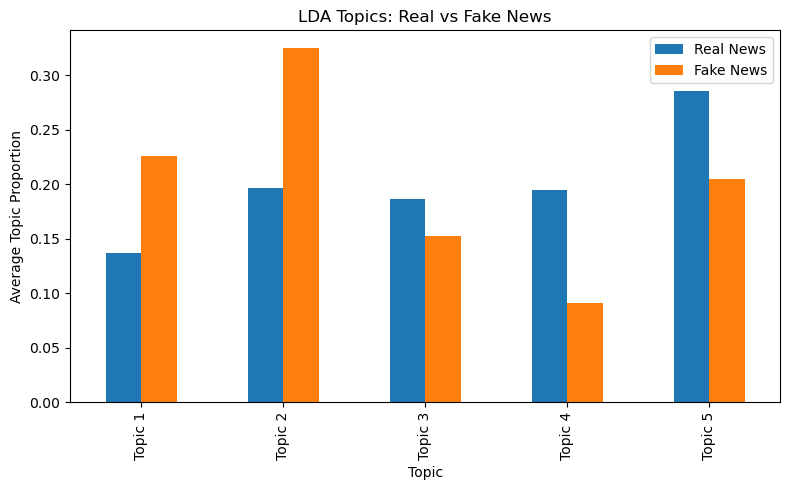

In [9]:
result.plot(x="Topic", y=["Real News", "Fake News"], kind="bar", figsize=(8, 5))

plt.title("LDA Topics: Real vs Fake News")
plt.ylabel("Average Topic Proportion")
plt.tight_layout()
plt.show()